In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## reward-distribution

**Figure 1: Reward-model scores of 400 responses from each policy.** Violins show the kernel density of the scores; the line marks the median. Scores split into a low-reward and a high-reward mode, and ours places 92% of responses in the high-reward mode (score > 0), against 45% for SFT and 67% for PPO.

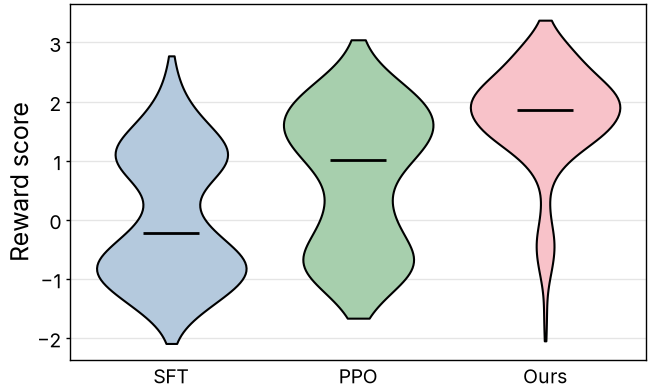

In [2]:
with open("../reward-distribution.json") as f:
    rewards = json.load(f)["rewards"]

policies = ["SFT", "PPO", "Ours"]
policy_colors = {"SFT": colors["series-1"], "PPO": colors["series-3"], "Ours": colors["ours"]}

fig, ax = plt.subplots(figsize=(3.25, 2), layout="constrained")
for x, name in enumerate(policies):
    values = rewards[name]
    parts = ax.violinplot(values, positions=[x], widths=0.8, showextrema=False)
    body = parts["bodies"][0]
    body.set_facecolor(lighten(policy_colors[name]))
    body.set_edgecolor("black")
    body.set_linewidth(0.75)
    body.set_alpha(1)
    ax.hlines(np.median(values), x - 0.15, x + 0.15, color="black", linewidth=1)

ax.set_xticks(range(len(policies)), labels=policies)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Reward score")

fit_height(fig, ax, aspect=0.618)
fig.savefig("reward-distribution.pdf")
fig.savefig("reward-distribution.png")
plt.show()